# Lab 2: Probability, Naive Bayes Classification and Outlier Detection

**Student Name:** Ved Vishal Patel  
**Student ID:** 9111628  
**Course:** CSCN8000

## Introduction

In this lab, I will explore how probability and statistics can be used to solve two different problems.

In Part A, I will build and compare Gaussian Naive Bayes and Multinomial Naive Bayes models to classify emails as spam or not spam.

In Part B, I will explore Airbnb prices in New York City and apply statistical techniques to identify and remove unusual price values.

The goal is to understand how machine learning can help with classification and how statistical methods can improve data quality.

I import the libraries used throughout the lab for data handling, plotting, splitting the data, training Naive Bayes models, and evaluating predictions.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("All libraries imported successfully!")

All libraries imported successfully!


## Part A: Spam Email Classification

Naive Bayes is a machine learning algorithm that uses probability to make predictions.

For example, an email containing words such as "free", "prize", or "winner" may have a higher chance of being spam.

In this part, I will compare two classifiers:

- **Gaussian Naive Bayes:** Assumes each feature follows a normal (bell-shaped) distribution within each class.
- **Multinomial Naive Bayes:** Commonly used with word counts or frequencies, making it useful for text classification.

I will compare their performance on the same test dataset to see which works better.

I load the spam dataset and display its dimensions, column names, and first few rows to understand its structure.

In [2]:
spam_df = pd.read_csv("Lab2_dataset.csv")

print("Dataset shape:", spam_df.shape)
print("\nColumn names:")
print(spam_df.columns.tolist())

display(spam_df.head())

Dataset shape: (5171, 4)

Column names:
['Unnamed: 0', 'label', 'text', 'label_num']


,Unnamed: 0,label,text,label_num
0,605,ham,Subject: enron methanol ; meter # : 988291\nth...,0
1,2349,ham,"Subject: hpl nom for january 9 , 2001\n( see a...",0
2,3624,ham,"Subject: neon retreat\nho ho ho , we ' re arou...",0
3,4685,spam,"Subject: photoshop , windows , office . cheap ...",1
4,2030,ham,Subject: re : indian springs\nthis deal is to ...,0


I check the spam dataset's data types, missing values, duplicate rows, and descriptive statistics before preparing it for modeling.

In [3]:
print("Dataset information:")
spam_df.info()

print("\nMissing values:")
print(spam_df.isnull().sum())

print("\nDuplicate rows:", spam_df.duplicated().sum())

display(spam_df.describe(include="all"))

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 5171 entries, 0 to 5170
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Unnamed: 0  5171 non-null   int64
 1   label       5171 non-null   str  
 2   text        5171 non-null   str  
 3   label_num   5171 non-null   int64
dtypes: int64(2), str(2)
memory usage: 161.7 KB

Missing values:
Unnamed: 0    0
label         0
text          0
label_num     0
dtype: int64

Duplicate rows: 0


,Unnamed: 0,label,text,label_num
count,5171.000000,5171,5171,5171.000000
unique,NaN,2,4993,NaN
top,NaN,ham,Subject: calpine daily gas nomination\n>\nrick...,NaN
freq,NaN,3672,20,NaN
mean,2585.000000,NaN,NaN,0.289886
std,1492.883452,NaN,NaN,0.453753
min,0.000000,NaN,NaN,0.000000
25%,1292.500000,NaN,NaN,0.000000
50%,2585.000000,NaN,NaN,0.000000
75%,3877.500000,NaN,NaN,1.000000


I identify the label column and choose either message text or numeric features. I handle missing feature values and encode the labels for model training.

In [4]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.preprocessing import LabelEncoder

# Find the column containing spam/not-spam labels.
target_names = [
    "spam", "label", "class", "category",
    "target", "is_spam", "type"
]

target_col = next(
    (col for col in spam_df.columns
     if col.lower().strip() in target_names),
    None
)

if target_col is None:
    raise ValueError(
        "Target column not identified. Check the columns "
        "printed in Cell 4 and set target_col manually."
    )

df_a = spam_df.dropna(subset=[target_col]).copy()
y_raw = df_a[target_col]

# Check for a text-message column.
text_names = [
    "text", "message", "email", "sms",
    "body", "content", "v2"
]

text_col = next(
    (col for col in df_a.columns
     if col.lower().strip() in text_names
     and col != target_col),
    None
)

# If there is no text column, use numeric features.
if text_col is None:
    features = df_a.drop(columns=[target_col])
    features = features.select_dtypes(include=np.number)

    if features.empty:
        raise ValueError(
            "No numeric features found. Inspect Cell 4."
        )

    X = features.fillna(features.median()).clip(lower=0)
    feature_mode = "numeric"

else:
    X = df_a[text_col].fillna("").astype(str)
    feature_mode = "text"

encoder = LabelEncoder()
y = encoder.fit_transform(y_raw.astype(str))

print("Target column:", target_col)
print("Feature mode:", feature_mode)
print("Classes:", encoder.classes_)
print("Number of samples:", len(y))

Target column: label
Feature mode: text
Classes: ['ham' 'spam']
Number of samples: 5171


I split the features and labels into training and testing sets, keeping 20% for testing and preserving the class proportions.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 4136
Testing samples: 1035


I convert message text into word-count features with a vectorizer, or pass through the numeric features, so both models can use the data.

In [6]:
if feature_mode == "text":
    vectorizer = CountVectorizer()

    X_train_ready = vectorizer.fit_transform(X_train)
    X_test_ready = vectorizer.transform(X_test)

else:
    X_train_ready = X_train
    X_test_ready = X_test

print("Features are ready for training.")

Features are ready for training.


I train Gaussian Naive Bayes and Multinomial Naive Bayes on the training data, converting text features to a dense array for Gaussian Naive Bayes.

In [7]:
# GaussianNB expects a dense array.
if feature_mode == "text":
    X_train_gaussian = X_train_ready.toarray()
    X_test_gaussian = X_test_ready.toarray()
else:
    X_train_gaussian = X_train_ready
    X_test_gaussian = X_test_ready

gaussian_model = GaussianNB()
gaussian_model.fit(X_train_gaussian, y_train)

multinomial_model = MultinomialNB()
multinomial_model.fit(X_train_ready, y_train)

print("Both models trained successfully!")

Both models trained successfully!


I use both trained models to predict labels for the test set and display a small sample of predictions alongside the actual labels.

In [8]:
gaussian_pred = gaussian_model.predict(X_test_gaussian)
multinomial_pred = multinomial_model.predict(X_test_ready)

print("Gaussian predictions:", gaussian_pred[:10])
print("Multinomial predictions:", multinomial_pred[:10])
print("Actual labels:", y_test[:10])

Gaussian predictions: [0 0 0 0 0 1 0 0 0 1]
Multinomial predictions: [0 0 0 0 0 1 0 0 0 1]
Actual labels: [0 0 0 0 0 1 0 0 0 1]


I calculate and plot each model's test accuracy, then identify which model has the higher accuracy.

,Model,Accuracy
0,Gaussian Naive Bayes,0.954589
1,Multinomial Naive Bayes,0.976812


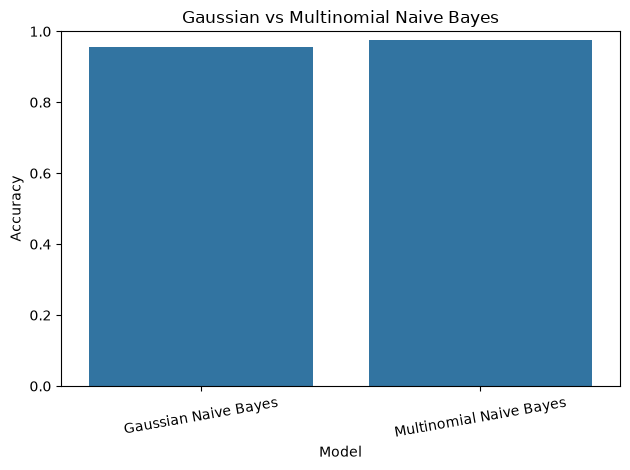

Better model based on accuracy: Multinomial Naive Bayes


In [9]:
gaussian_accuracy = accuracy_score(
    y_test, gaussian_pred
)

multinomial_accuracy = accuracy_score(
    y_test, multinomial_pred
)

results = pd.DataFrame({
    "Model": [
        "Gaussian Naive Bayes",
        "Multinomial Naive Bayes"
    ],
    "Accuracy": [
        gaussian_accuracy,
        multinomial_accuracy
    ]
})

display(results)

sns.barplot(data=results, x="Model", y="Accuracy")
plt.title("Gaussian vs Multinomial Naive Bayes")
plt.ylim(0, 1)
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

winner = results.loc[
    results["Accuracy"].idxmax(), "Model"
]

print("Better model based on accuracy:", winner)

I compare the models using precision, recall, F1-score, and confusion matrices to see how well each class is predicted.

Gaussian Naive Bayes:
              precision    recall  f1-score   support

         ham       0.96      0.98      0.97       735
        spam       0.94      0.90      0.92       300

    accuracy                           0.95      1035
   macro avg       0.95      0.94      0.94      1035
weighted avg       0.95      0.95      0.95      1035


Multinomial Naive Bayes:
              precision    recall  f1-score   support

         ham       0.98      0.99      0.98       735
        spam       0.97      0.95      0.96       300

    accuracy                           0.98      1035
   macro avg       0.98      0.97      0.97      1035
weighted avg       0.98      0.98      0.98      1035



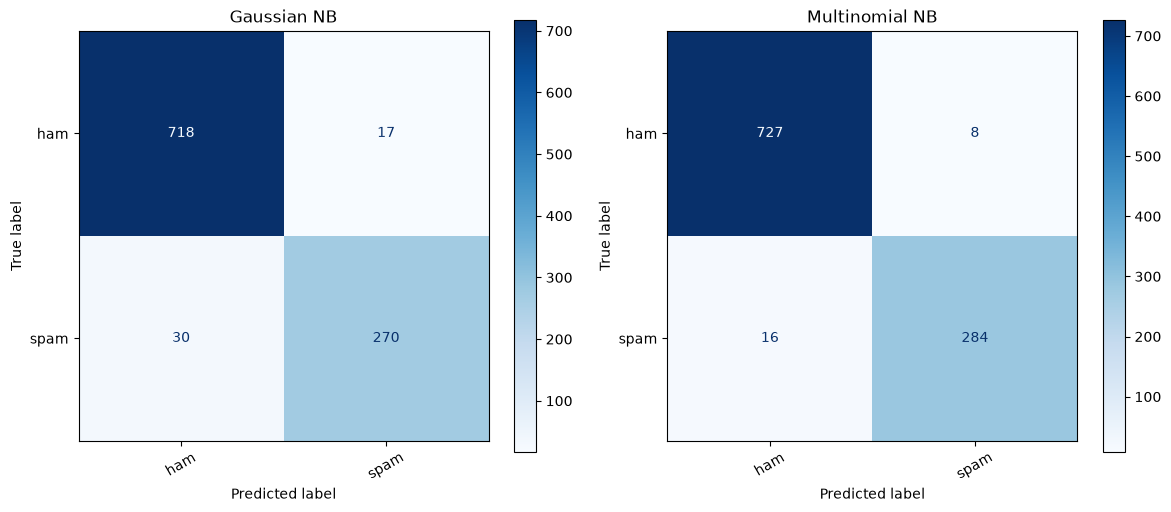

In [10]:
print("Gaussian Naive Bayes:")
print(classification_report(
    y_test,
    gaussian_pred,
    target_names=[str(x) for x in encoder.classes_],
    zero_division=0
))

print("\nMultinomial Naive Bayes:")
print(classification_report(
    y_test,
    multinomial_pred,
    target_names=[str(x) for x in encoder.classes_],
    zero_division=0
))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, predictions, title in zip(
    axes,
    [gaussian_pred, multinomial_pred],
    ["Gaussian NB", "Multinomial NB"]
):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        display_labels=encoder.classes_,
        ax=ax,
        cmap="Blues",
        xticks_rotation=30
    )
    ax.set_title(title)

plt.tight_layout()
plt.show()

I create a table of the first ten test examples showing the actual class and each model's predicted class.

In [11]:
prediction_table = pd.DataFrame({
    "Actual": encoder.inverse_transform(y_test[:10]),
    "Gaussian Prediction": encoder.inverse_transform(
        gaussian_pred[:10]
    ),
    "Multinomial Prediction": encoder.inverse_transform(
        multinomial_pred[:10]
    )
})

display(prediction_table)

,Actual,Gaussian Prediction,Multinomial Prediction
0,ham,ham,ham
1,ham,ham,ham
2,ham,ham,ham
3,ham,ham,ham
4,ham,ham,ham
5,spam,spam,spam
6,ham,ham,ham
7,ham,ham,ham
8,ham,ham,ham
9,spam,spam,spam


### Part A Conclusion

I trained two Naive Bayes classification models using an 80/20 train-test split.

I compared Gaussian Naive Bayes and Multinomial Naive Bayes using accuracy, precision, recall, F1-score, and confusion matrices.

The test results show which model performs better on this dataset. The classification reports also help identify whether the models are missing spam emails or incorrectly marking normal emails as spam.

Based on the results above, I can select the better-performing model for this classification problem.

## Part B: Airbnb NYC Price Outlier Detection

In this section, I will work with the New York City Airbnb dataset from 2019.

The main goal is to find unusual prices and create a cleaner dataset for analysis.

I will explore the price distribution, calculate statistical measures, and compare different techniques for detecting outliers.

I will also look at the effect of removing outliers on the mean, median, and overall distribution of prices.

Not every expensive listing is incorrect, but unusually extreme prices can affect statistical analysis.

I load the NYC Airbnb dataset, report its dimensions, and preview the first few listings.

In [12]:
airbnb = pd.read_csv("AB_NYC_2019.csv")

print("Dataset shape:", airbnb.shape)

display(airbnb.head())

Dataset shape: (48895, 16)


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


I review missing prices, summarize the price distribution, and count missing values across the Airbnb columns.

In [13]:
print("Missing prices:")
print(airbnb["price"].isnull().sum())

print("\nPrice statistics:")
display(airbnb["price"].describe())

print("\nMissing values in other columns:")
print(airbnb.isnull().sum())

Missing prices:
0

Price statistics:


count    48895.000000
mean       152.720687
std        240.154170
min          0.000000
25%         69.000000
50%        106.000000
75%        175.000000
max      10000.000000
Name: price, dtype: float64


Missing values in other columns:
id                                    0
name                                 16
host_id                               0
host_name                            21
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                       10052
reviews_per_month                 10052
calculated_host_listings_count        0
availability_365                      0
dtype: int64


I remove listings with missing or non-positive prices and report how many records remain and how many were removed.

In [14]:
price_data = airbnb.dropna(subset=["price"]).copy()

price_data = price_data[
    price_data["price"] > 0
].copy()

print("Original rows:", len(airbnb))
print("Rows with valid positive prices:", len(price_data))
print("Rows removed:", len(airbnb) - len(price_data))

Original rows: 48895
Rows with valid positive prices: 48884
Rows removed: 11


I plot a histogram and boxplot of valid nightly prices to inspect their distribution and potential extreme values.

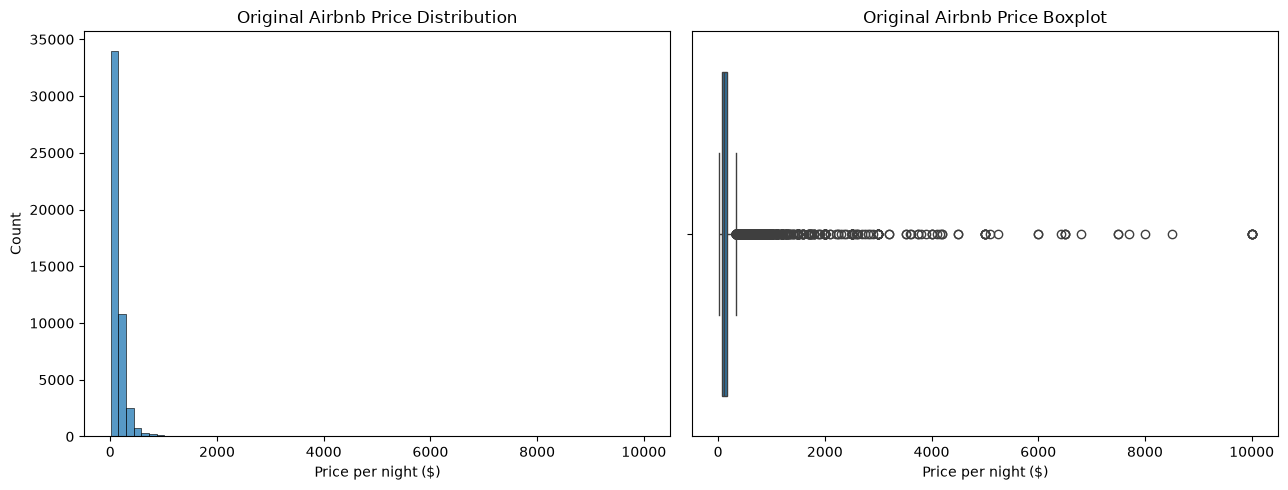

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(
    price_data["price"],
    bins=70,
    ax=axes[0]
)
axes[0].set_title("Original Airbnb Price Distribution")
axes[0].set_xlabel("Price per night ($)")

sns.boxplot(
    x=price_data["price"],
    ax=axes[1]
)
axes[1].set_title("Original Airbnb Price Boxplot")
axes[1].set_xlabel("Price per night ($)")

plt.tight_layout()
plt.show()

I calculate the mean, median, and standard deviation of valid Airbnb prices for use in summary and outlier analysis.

In [16]:
mean_price = price_data["price"].mean()
median_price = price_data["price"].median()
std_price = price_data["price"].std()

print(f"Mean price: ${mean_price:.2f}")
print(f"Median price: ${median_price:.2f}")
print(f"Standard deviation: ${std_price:.2f}")

Mean price: $152.76
Median price: $106.00
Standard deviation: $240.17


### Statistical Methods for Outlier Detection

**Mean:** The average of all prices. It can be strongly affected by extremely expensive listings.

**Median:** The middle price after sorting the values. It is less sensitive to extreme values.

**Standard Deviation:** Measures how spread out prices are around the mean.

**Percentiles:** Help identify extreme portions of the dataset, such as the highest and lowest 1% of prices.

**IQR:** Uses the middle 50% of the data to identify values that are unusually low or high.

I will compare these techniques rather than assume that one method is always the best.

I calculate IQR-based price limits and retain listings within those limits, reporting the thresholds and remaining row count.

In [17]:
Q1 = price_data["price"].quantile(0.25)
Q3 = price_data["price"].quantile(0.75)

IQR = Q3 - Q1

lower_iqr = Q1 - 1.5 * IQR
upper_iqr = Q3 + 1.5 * IQR

iqr_clean = price_data[
    price_data["price"].between(lower_iqr, upper_iqr)
].copy()

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower_iqr)
print("Upper limit:", upper_iqr)
print("Rows remaining:", len(iqr_clean))

Q1: 69.0
Q3: 175.0
IQR: 106.0
Lower limit: -90.0
Upper limit: 334.0
Rows remaining: 45912


I remove prices below the 1st or above the 99th percentile to create a percentile-based comparison dataset.

In [18]:
lower_percentile = price_data["price"].quantile(0.01)
upper_percentile = price_data["price"].quantile(0.99)

percentile_clean = price_data[
    price_data["price"].between(
        lower_percentile,
        upper_percentile
    )
].copy()

print("1st percentile:", lower_percentile)
print("99th percentile:", upper_percentile)
print("Rows remaining:", len(percentile_clean))

1st percentile: 30.0
99th percentile: 799.0
Rows remaining: 48017


I use the mean plus or minus three standard deviations as bounds and count the listings within those limits.

In [19]:
lower_std = mean_price - 3 * std_price
upper_std = mean_price + 3 * std_price

std_clean = price_data[
    price_data["price"].between(
        lower_std,
        upper_std
    )
].copy()

print("Lower limit:", lower_std)
print("Upper limit:", upper_std)
print("Rows remaining:", len(std_clean))

Lower limit: -567.7557275491137
Upper limit: 873.2658331051238
Rows remaining: 48496


I calculate the median absolute deviation and modified z-scores, then retain listings whose absolute modified z-score is at most 3.5.

In [20]:
median = price_data["price"].median()

absolute_deviations = (
    price_data["price"] - median
).abs()

mad = absolute_deviations.median()

if mad == 0:
    raise ValueError(
        "MAD is zero. Choose a different method."
    )

modified_z = (
    0.6745 * (price_data["price"] - median) / mad
)

mad_clean = price_data[
    modified_z.abs() <= 3.5
].copy()

print("Median:", median)
print("MAD:", mad)
print("Rows remaining:", len(mad_clean))

Median: 106.0
MAD: 46.0
Rows remaining: 45968


I compare the original valid-price data and each outlier method by row counts and price summaries.

In [21]:
methods = {
    "Original positive-price data": price_data,
    "IQR": iqr_clean,
    "Percentiles (1%-99%)": percentile_clean,
    "Mean +/- 3 SD": std_clean,
    "Median + MAD": mad_clean
}

comparison = pd.DataFrame([
    {
        "Method": name,
        "Rows": len(df),
        "Rows Removed": len(price_data) - len(df),
        "Mean Price": round(df["price"].mean(), 2),
        "Median Price": round(df["price"].median(), 2),
        "Maximum Price": df["price"].max()
    }
    for name, df in methods.items()
])

display(comparison)

,Method,Rows,Rows Removed,Mean Price,Median Price,Maximum Price
0,Original positive-price data,48884,0,152.76,106.0,10000
1,IQR,45912,2972,120.00,100.0,334
2,Percentiles (1%-99%),48017,867,138.50,105.0,799
3,Mean +/- 3 SD,48496,388,138.78,105.0,860
4,Median + MAD,45968,2916,120.27,100.0,344


I plot the price distributions remaining after each outlier method to compare their effects visually.

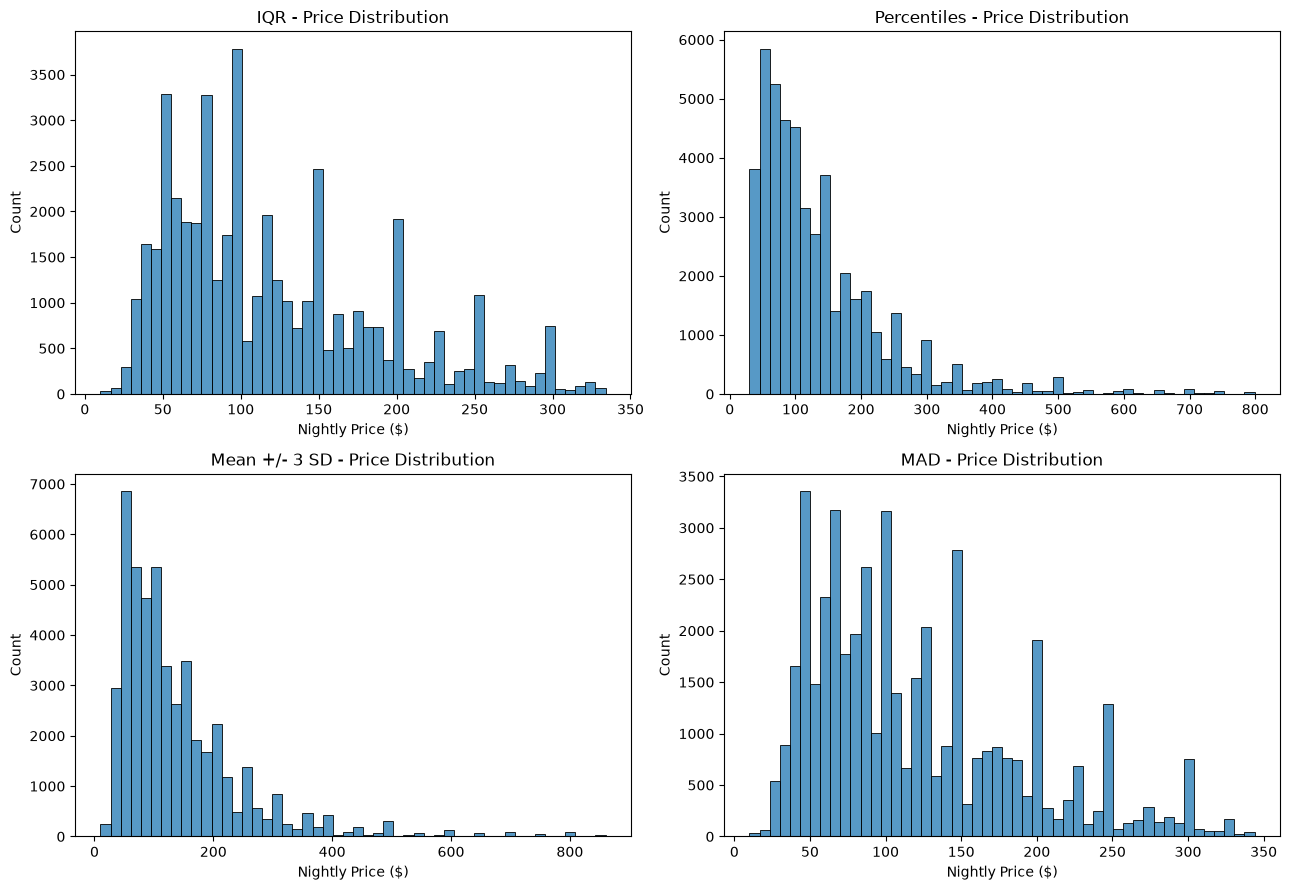

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

cleaned_methods = [
    ("IQR", iqr_clean),
    ("Percentiles", percentile_clean),
    ("Mean +/- 3 SD", std_clean),
    ("MAD", mad_clean)
]

for ax, (name, df) in zip(axes.flat, cleaned_methods):
    sns.histplot(
        df["price"],
        bins=50,
        ax=ax
    )
    ax.set_title(f"{name} - Price Distribution")
    ax.set_xlabel("Nightly Price ($)")

plt.tight_layout()
plt.show()

### Selecting the Final Cleaning Method

After comparing the different statistical techniques, I selected IQR as my main cleaning method.

IQR uses the middle 50% of prices and does not depend on the mean, which can be strongly influenced by expensive listings.

The percentile method also works, but its cutoff values are based on fixed proportions of the data.

The mean and standard deviation method is less suitable when the distribution is strongly skewed.

The MAD method is another robust option, but IQR is straightforward to explain and visualize using quartiles and boxplots.

I will preserve the original dataset and save a separate cleaned version. The removed listings are statistical outliers under my chosen rule, not necessarily incorrect listings.

I select the IQR-filtered data as the final dataset, save it as a CSV file, and report the number of records retained and excluded.

In [23]:
clean_airbnb = iqr_clean.copy()

clean_airbnb.to_csv(
    "Airbnb_NYC_Cleaned.csv",
    index=False
)

print("Clean dataset saved successfully!")
print("Original records:", len(airbnb))
print("Clean records:", len(clean_airbnb))
print(
    "Records excluded:",
    len(airbnb) - len(clean_airbnb)
)

Clean dataset saved successfully!
Original records: 48895
Clean records: 45912
Records excluded: 2983


I summarize the cleaned prices, verify that no retained values fall outside the IQR limits, and plot the cleaned price distribution.

Final cleaned dataset statistics:


count    45912.000000
mean       119.999063
std         68.133003
min         10.000000
25%         65.000000
50%        100.000000
75%        159.000000
max        334.000000
Name: price, dtype: float64

Values outside the chosen IQR limits: 0


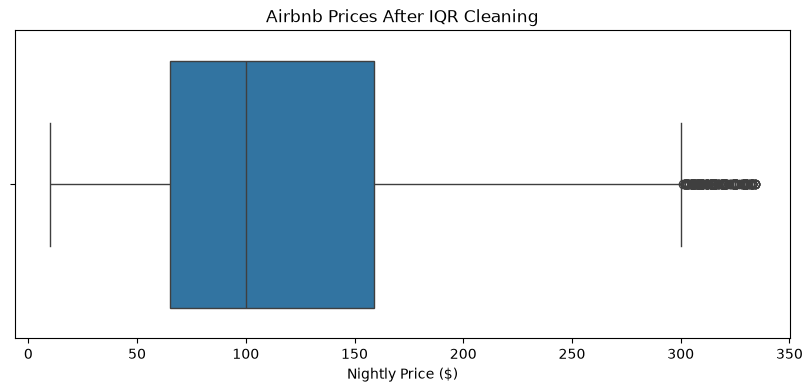

In [24]:
print("Final cleaned dataset statistics:")
display(clean_airbnb["price"].describe())

# Verify that every retained price follows
# the original IQR cutoff.
remaining_outliers = (
    ~clean_airbnb["price"].between(
        lower_iqr, upper_iqr
    )
).sum()

print(
    "Values outside the chosen IQR limits:",
    remaining_outliers
)

plt.figure(figsize=(10, 4))
sns.boxplot(x=clean_airbnb["price"])
plt.title("Airbnb Prices After IQR Cleaning")
plt.xlabel("Nightly Price ($)")
plt.show()

## Final Conclusion

In this lab, I learned how probability and statistics can be applied to different data problems.

In Part A, I trained Gaussian Naive Bayes and Multinomial Naive Bayes classifiers to predict whether emails were spam or not spam. I compared the models using accuracy and additional evaluation metrics.

In Part B, I explored nightly prices in the New York City Airbnb dataset and applied four statistical methods to identify unusual values.

I compared IQR, percentiles, mean with standard deviation, and Median Absolute Deviation (MAD). I selected IQR as the final approach and exported a separate cleaned dataset.

This exercise helped me understand that choosing an appropriate method is important because different methods can produce different results.